In [1]:
# ─────────────────────────────────────────────────────────────────────────────
# Standard Library Imports

# ─────────────────────────────────────────────────────────────────────────────
# Third-Party Imports
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import polars as pl
import matplotlib.pyplot as plt

import seaborn as sns
from datetime import timedelta
from typing import List
from pathlib import Path
from typing import List

# Define Seaborn style
def set_academic_style():
    
    # Color Universal Design Palette
    color_palette = [
        "#377eb8",  # azul
        "#ff7f00",  # naranja
        "#4daf4a",  # verde
        "#f781bf",  # rosa
        "#a65628",  # marrón
        "#984ea3",  # púrpura
        "#999999",  # gris
        "#e41a1c",  # rojo
        "#dede00"   # amarillo
    ]

    # Style
    sns.set(
        style="whitegrid",
        palette=color_palette,
        context="paper",
        font_scale=1.5
    )

    # Additional Matplotlib Config
    plt.rcParams.update({
        "figure.figsize": (10, 6),
        "axes.titlesize": 18,
        "axes.labelsize": 14,
        "axes.labelweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "legend.fontsize": 12,
        "legend.title_fontsize": 14,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "savefig.dpi": 300,
        "savefig.format": "pdf"
    })

set_academic_style()

# Input

In [2]:
def datasetsCreator(csv_files):
    # Leer y procesar cada archivo
    datasets: List[pl.DataFrame] = []
    for filepath in csv_files:
        df: pl.DataFrame = pl.read_csv(filepath)
        df = df.with_columns([
            (
                (pl.col("timestamp") - pl.col("timestamp").min())
                .cast(pl.Duration("ns")) + pl.lit(0).cast(pl.Datetime("ns"))
            ).alias("timestamp"),
            pl.col("value").cast(pl.Int64)
        ])
        # Filter PTP metrics
        df_ptp = df.filter(
            pl.col("metric").str.contains("PPS") | 
            pl.col("metric").str.contains("offset")
            )

        # PTP Correspondence
        ptp_map = {
            "PPS_3_PPSAnalyzer": "TimeStick_hw_offset",
            "PPS_4_PPSAnalyzer": "Intel710_hw_offset",
            "PPS_5_PPSAnalyzer": "Intel810_hw_offset",
            "offset_TimeStick_PTP_Log": "TimeStick_sw_offset",
            "offset_Intel710_PTP_Log": "Intel710_sw_offset",
            "offset_Intel810_PTP_Log": "Intel810_sw_offset",
        }

        # Name Replacement
        df_ptp = df_ptp.with_columns(
            pl.col("metric").replace(ptp_map).alias("PTP_metric"),
            pl.col("value").alias("offset_ns")
        ).drop("metric", "value")

        # Hardware PTP Dataframe
        df_hw_ptp = df_ptp.filter(
            pl.col("PTP_metric").str.contains("hw")
        ).rename({
            "offset_ns": "offset_hw_ns",
            "PTP_metric":"PTP_client",
        }).with_columns(
            pl.col("PTP_client").replace(
                {
                    "TimeStick_hw_offset": "TimeStick",
                    "Intel710_hw_offset": "Intel710",
                    "Intel810_hw_offset": "Intel810",
                }
            )
        )#.filter(pl.col("timestamp") >= pl.col("timestamp").min() + pl.duration(minutes=8))
        
        datasets.append(df_hw_ptp)
    return datasets

def load_datasets(base_dir: str, prefix: str, durations: List[int], suffix: str) -> List[List[pl.DataFrame]]:
    all_datasets: List[List[pl.DataFrame]] = []
    for duration in durations:
        time_label = f"T{duration}"
        dir_path = Path(f"{base_dir}/{prefix}-{time_label}-{suffix}")
        pattern = f"{prefix}-{time_label}-{suffix}_*.csv"
        csv_files: List[Path] = list(dir_path.glob(pattern))
        datasets: List[pl.DataFrame] = datasetsCreator(csv_files)
        all_datasets.append(datasets)
    return all_datasets

In [3]:
loads = [0, 25, 50, 75]
durations = [60]

# IDLE
datasets_0_by_time_IDLE = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L0", durations, "IDLE")
datasets_25_by_time_TM1 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L25", durations, "TM1")
datasets_25_by_time_TM3 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L25", durations, "TM3")
datasets_50_by_time_TM1 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L50", durations, "TM1")
datasets_50_by_time_TM3 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L50", durations, "TM3")
datasets_75_by_time_TM1 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L75", durations, "TM1")
datasets_75_by_time_TM3 = load_datasets("../output/Ly3_CTStab", "Ly3_CTStab_L75", durations, "TM3")

# Basic Plots

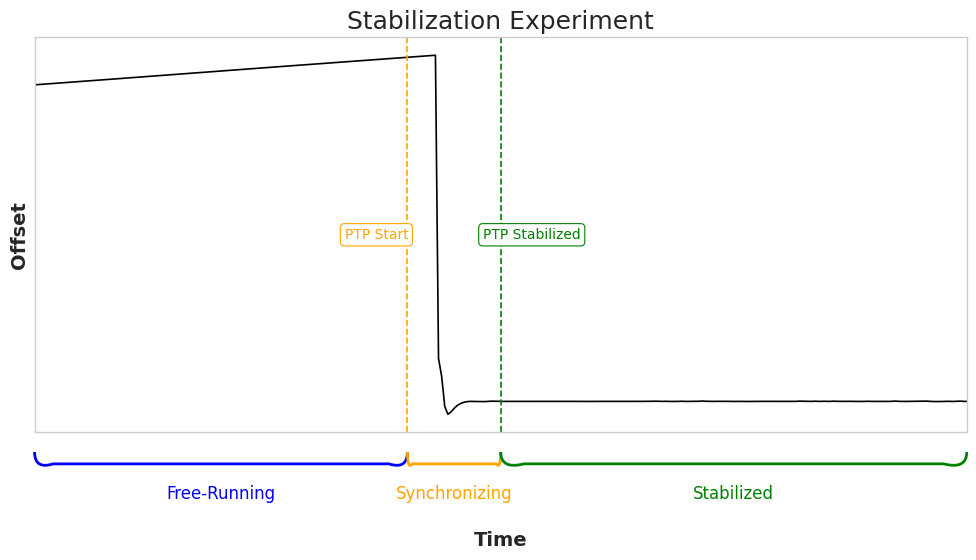

In [4]:
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import polars as pl

def print_graphs(df: pl.DataFrame, client: str) -> None:
    df = df.filter(pl.col("PTP_client") == client)

    # Definir inicio absoluto en 00:00:00
    start_time = datetime(1970, 1, 1, 0, 0, 0)
    start_time_xlim = start_time + timedelta(minutes=8)
    end_time = start_time + timedelta(minutes=13)

    df = df.filter((pl.col("timestamp") >= start_time) & (pl.col("timestamp") <= end_time))

    timestamps = df.get_column("timestamp").to_list()
    offsets = df.get_column("offset_hw_ns").to_list()

    fig, ax = plt.subplots()
    ax.plot(timestamps, offsets, label="offset_hw_ns", color="black")

    ax.set_xlim(start_time_xlim, end_time)

    # Líneas discontinuas
    ptp_start = start_time + timedelta(minutes=10)
    ax.axvline(x=ptp_start, color='orange', linestyle='--')
    ptp_stab = start_time + timedelta(minutes=10, seconds=30)
    ax.axvline(x=ptp_stab, color='green', linestyle='--')

    # Obtener centro vertical del gráfico
    center_y = (ax.get_ylim()[0] + ax.get_ylim()[1]) / 2

    # Anotación PTP Start (centrada en el gráfico)
    ax.annotate("PTP Start",
                xy=(ptp_start, center_y),
                xytext=(ptp_start + timedelta(seconds=-10), center_y),
                textcoords="data",
                fontsize=10, color='orange', ha='center', va='center',
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="orange"))

    # Anotación PTP Stabilized (centrada en el gráfico)
    ax.annotate("PTP Stabilized",
                xy=(ptp_stab, center_y),
                xytext=(ptp_stab + timedelta(seconds=10), center_y),
                textcoords="data",
                fontsize=10, color='green', ha='center', va='center',
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="green"))


    # Parámetros comunes para corchetes
    y_bracket = ax.get_ylim()[0] - (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.05  # pegado al eje X
    height = 0.03 * (ax.get_ylim()[1] - ax.get_ylim()[0])
    control_offset = height * 1.5
    Path = mpath.Path
    codes = [Path.MOVETO, Path.CURVE3, Path.CURVE3, Path.LINETO, Path.CURVE3, Path.CURVE3]

    def draw_bracket(x1, x2, color, label):
        verts = [
            (x1, y_bracket), (x1, y_bracket - control_offset),
            (x1 + (x2 - x1) * 0.05, y_bracket - height),
            (x2 - (x2 - x1) * 0.05, y_bracket - height),
            (x2, y_bracket - control_offset), (x2, y_bracket)
        ]
        patch = mpatches.PathPatch(Path(verts, codes), edgecolor=color, linewidth=2, facecolor="none", clip_on=False)
        ax.add_patch(patch)
        ax.text((x1 + x2) / 2, y_bracket - height * 4, label, ha="center", fontsize=12, color=color)

    # Corchete 1: inicio → ptp_start
    draw_bracket(mdates.date2num(start_time_xlim), mdates.date2num(ptp_start), "blue", "Free-Running")

    # Corchete 2: ptp_start → ptp_stab
    draw_bracket(mdates.date2num(ptp_start), mdates.date2num(ptp_stab), "orange", "Synchronizing")

    # Corchete 3: ptp_stab → fin
    draw_bracket(mdates.date2num(ptp_stab), mdates.date2num(end_time), "green", "Stabilized")

    # Ajustes del eje X
    ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter(''))
    ax.xaxis.set_tick_params(labelrotation=45, labelsize=10)

    ax.yaxis.set_ticks([])

    ax.set_xlabel("Time", labelpad=20)
    ax.xaxis.set_label_coords(0.5, -0.25)  
    ax.set_ylabel("Offset")
    ax.set_title("Stabilization Experiment")
    ax.grid(False)
    plt.tight_layout()
    plt.show()


# Ejecutar la función con el DataFrame simulado
print_graphs(datasets_50_by_time_TM1[0][0],"TimeStick")


# Time Stabilization

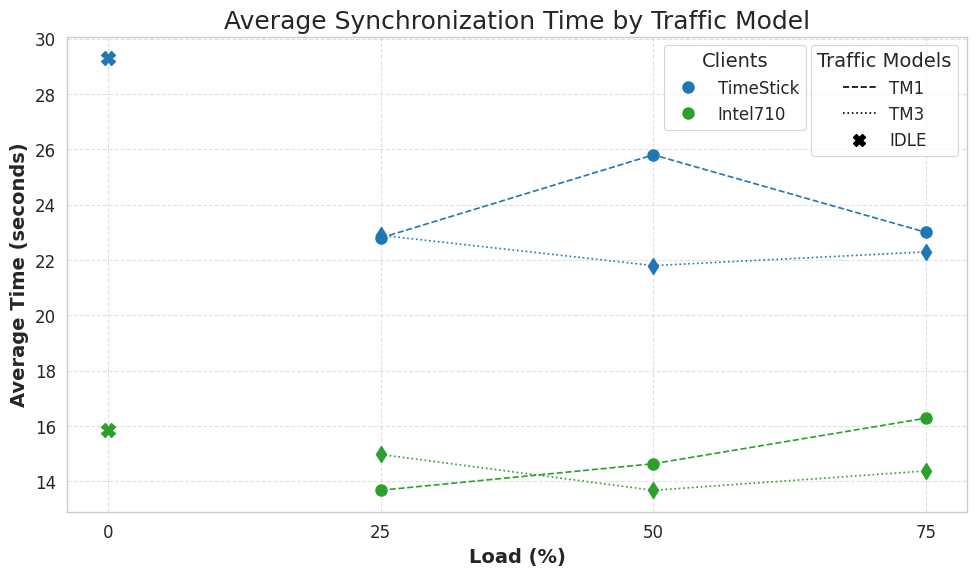

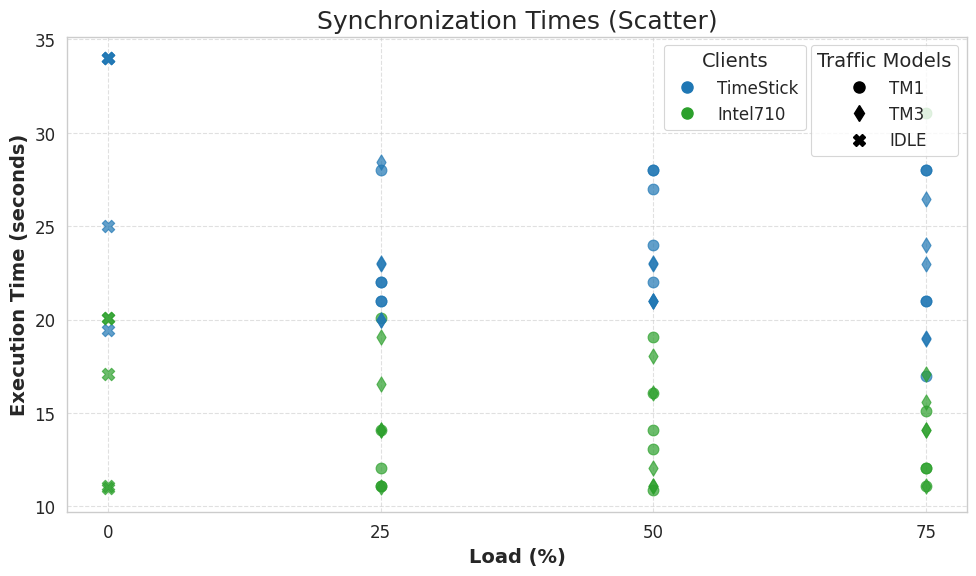

In [5]:
from typing import List
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

def plot_avg_sync_time_all(csv_path: str) -> None:
    # Read CSV file
    df: pl.DataFrame = pl.read_csv(csv_path)

    # Interpret IDLE as load = 0
    df = df.with_columns(
        pl.when(pl.col("traffic") == "IDLE")
        .then(0)
        .otherwise(pl.col("load"))
        .alias("load")
    )

    # Convert execution columns (E0-E4) to seconds manually
    execution_cols: List[str] = ["E0", "E1", "E2", "E3", "E4"]
    for col in execution_cols:
        df = df.with_columns(
            pl.col(col)
            .str.split(":")
            .map_elements(lambda parts: int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2]), return_dtype=pl.Float64)
            .alias(col)
        )

    # Calculate average time across executions
    df_avg: pl.DataFrame = df.with_columns(
        ((pl.col("E0") + pl.col("E1") + pl.col("E2") + pl.col("E3") + pl.col("E4")) / 5)
        .alias("avg_time")
    ).select(["load", "client", "traffic", "avg_time"])

    # Prepare plot
    plt.figure(figsize=(10, 6))
    line_styles = {"IDLE": "", "TM1": "--", "TM3": ":"}  # IDLE no tiene línea
    marker_styles = {"IDLE": "X", "TM1": "o", "TM3": "d"}
    marker_sizes = {"IDLE": 10, "TM1": 8, "TM3": 8}
    colors = {"TimeStick": "tab:blue", "Intel710": "tab:green"}

    # Plot each traffic type for each client
    for traffic in ["IDLE", "TM1", "TM3"]:
        for client in ["TimeStick", "Intel710"]:
            subset = df_avg.filter((pl.col("traffic") == traffic) & (pl.col("client") == client))
            loads: List[int] = subset["load"].to_list()
            avg_times: List[float] = subset["avg_time"].to_list()
            plt.plot(loads, avg_times,
                     color=colors[client],
                     linestyle=line_styles[traffic],
                     marker=marker_styles[traffic],
                     markersize=marker_sizes[traffic])

    # Legend 1: Clients
    client_handles = [
        Line2D([0], [0], color=colors["TimeStick"], marker="o", markersize=8, linestyle="", label="TimeStick"),
        Line2D([0], [0], color=colors["Intel710"], marker="o", markersize=8, linestyle="", label="Intel710")
    ]
    legend1 = plt.legend(handles=client_handles, title="Clients", loc="upper right", bbox_to_anchor=(0.83, 1))

    # Legend 2: Traffic models (line styles only)
    traffic_handles = [
        Line2D([0], [0], color="black", linestyle="--", label="TM1"),
        Line2D([0], [0], color="black", linestyle=":", label="TM3"),
        Line2D([0], [0], color="black", marker="X", linestyle="", markersize=8, label="IDLE")
    ]
    legend2 = plt.legend(handles=traffic_handles, title="Traffic Models", loc="upper right")

    plt.gca().add_artist(legend1)  # Add first legend back

    # Configure plot
    plt.title("Average Synchronization Time by Traffic Model")
    plt.xlabel("Load (%)")
    plt.ylabel("Average Time (seconds)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks([0, 25, 50, 75])
    plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

    # Show plot
    plt.tight_layout()
    plt.show()

# Run the function
plot_avg_sync_time_all("CStab.csv")



def plot_sync_time_scatter(csv_path: str) -> None:
    # Leer CSV
    df: pl.DataFrame = pl.read_csv(csv_path)

    # Interpretar IDLE como carga = 0
    df = df.with_columns(
        pl.when(pl.col("traffic") == "IDLE")
        .then(0)
        .otherwise(pl.col("load"))
        .alias("load")
    )

    # Convertir columnas E0-E4 a segundos
    execution_cols: List[str] = ["E0", "E1", "E2", "E3", "E4"]
    for col in execution_cols:
        df = df.with_columns(
            pl.col(col)
            .str.split(":")
            .map_elements(lambda parts: int(parts[0]) * 3600 + int(parts[1]) * 60 + float(parts[2]), return_dtype=pl.Float64)
            .alias(col)
        )

    # Configuración del gráfico
    plt.figure(figsize=(10, 6))
    marker_styles = {"IDLE": "X", "TM1": "o", "TM3": "d"}
    colors = {"TimeStick": "tab:blue", "Intel710": "tab:green"}
    marker_sizes = {"IDLE": 80, "TM1": 60, "TM3": 60}

    # Dibujar cada ejecución como punto
    for traffic in ["IDLE", "TM1", "TM3"]:
        for client in ["TimeStick", "Intel710"]:
            subset = df.filter((pl.col("traffic") == traffic) & (pl.col("client") == client))
            loads: List[int] = subset["load"].to_list()
            for col in execution_cols:
                times: List[float] = subset[col].to_list()
                plt.scatter(loads, times,
                            color=colors[client],
                            marker=marker_styles[traffic],
                            s=marker_sizes[traffic],
                            alpha=0.7)

    # Leyenda clientes
    client_handles = [
        Line2D([0], [0], color=colors["TimeStick"], marker="o", markersize=8, linestyle="", label="TimeStick"),
        Line2D([0], [0], color=colors["Intel710"], marker="o", markersize=8, linestyle="", label="Intel710")
    ]
    legend1 = plt.legend(handles=client_handles, title="Clients", loc="upper right", bbox_to_anchor=(0.83, 1))

    # Leyenda tráfico
    traffic_handles = [
        Line2D([0], [0], color="black", marker="o", linestyle="", markersize=8, label="TM1"),
        Line2D([0], [0], color="black", marker="d", linestyle="", markersize=8, label="TM3"),
        Line2D([0], [0], color="black", marker="X", linestyle="", markersize=8, label="IDLE")
    ]
    legend2 = plt.legend(handles=traffic_handles, title="Traffic Models", loc="upper right")

    plt.gca().add_artist(legend1)

    # Configuración general
    plt.title("Synchronization Times (Scatter)")
    plt.xlabel("Load (%)")
    plt.ylabel("Execution Time (seconds)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks([0, 25, 50, 75])
    plt.tight_layout()
    plt.show()

# Ejecutar
plot_sync_time_scatter("CStab.csv")

In [9]:

from __future__ import annotations
import pandas as pd
import numpy as np

def time_to_seconds(t: str) -> float:
    """Convierte un tiempo 'HH:MM:SS.mmmmmm' a segundos."""
    h, m, s = t.split(":")
    return int(h) * 3600 + int(m) * 60 + float(s)

def main() -> None:
    df: pd.DataFrame = pd.read_csv("CStab.csv")

    time_cols: list[str] = ["E0", "E1", "E2", "E3", "E4"]

    # Convertir a segundos
    for col in time_cols:
        df[col] = df[col].apply(time_to_seconds)

    clients: list[str] = df["client"].unique().tolist()

    for client in clients:
        print(f"\n=== Estadísticas para {client} ===")

        values: np.ndarray = df[df["client"] == client][time_cols].values.flatten()
        series: pd.Series = pd.Series(values)

        mean_val: float = series.mean()
        std_val: float = series.std()
        min_val: float = series.min()
        max_val: float = series.max()

        # Métricas relevantes adicionales
        q1: float = series.quantile(0.25)
        q3: float = series.quantile(0.75)
        iqr: float = q3 - q1

        cv: float = std_val / mean_val if mean_val != 0 else float("nan")

        print(f"Media:                {mean_val:.6f} s")
        print(f"Desviación típica:    {std_val:.6f} s")
        print(f"Mínimo:               {min_val:.6f} s")
        print(f"Máximo:               {max_val:.6f} s")
        print(f"IQR (Q3 - Q1):        {iqr:.6f} s")
        print(f"Coef. variación (CV): {cv:.6f}")

if __name__ == "__main__":
    main()



=== Estadísticas para TimeStick ===
Media:                23.980471 s
Desviación típica:    4.363953 s
Mínimo:               17.005827 s
Máximo:               33.996740 s
IQR (Q3 - Q1):        6.510734 s
Coef. variación (CV): 0.181979

=== Estadísticas para Intel710 ===
Media:                14.782223 s
Desviación típica:    4.166148 s
Mínimo:               10.865643 s
Máximo:               31.083877 s
IQR (Q3 - Q1):        5.718601 s
Coef. variación (CV): 0.281835

=== Estadísticas para Intel810 ===
Media:                2699.744837 s
Desviación típica:    6.815295 s
Mínimo:               2686.582564 s
Máximo:               2714.133181 s
IQR (Q3 - Q1):        10.618271 s
Coef. variación (CV): 0.002524


In [7]:
class SyRe:

    # Crear clase
    def __init__(self, df, w_p, th_cc,client_name):
        # Leer datos
        self.df = df
        self.client_name = client_name
        # Ventana procesamiento
        self.window_processing  = w_p
        # Calibración y umbrales
        self.th_cc_pos          = abs(th_cc)
        self.th_cc_neg          = -abs(th_cc)
        self.er_wait            = int(w_p/2)
        # Timestamps relevantes
        self.ts_fr              = []
        self.ts_t1              = []
        self.ts_sy              = []
        self.dt_fr              = []
        self.dt_t1              = []
        self.dt_sy              = []
        # States
        self.init               = True
        self.SyRe_state        = "FR"
        self.cycle              = 1
        # Processing
        self.rolling_process()
        
    # Procesar el dataset final
    def rolling_process(self):
        # States
        self.df = self.df.filter(
            pl.col("PTP_client") == self.client_name
        )
        self.df = self.df.with_columns(
            pl.Series("state", [""] * len(self.df)).cast(pl.Utf8),
        )
    
        # Rolling CorrCoefficient
        self.df = self.df.with_columns(
            pl.rolling_corr("timestamp","offset_hw_ns",window_size=self.window_processing).alias("r_cc"),
            pl.col("offset_hw_ns").rolling_mean(self.window_processing).alias("r_mean")
        ).with_columns(
            pl.when(pl.col("r_cc") > self.th_cc_pos).then(pl.lit(1))
            .when(pl.col("r_cc") < self.th_cc_neg).then(pl.lit(-1))
            .otherwise(pl.col("r_cc"))
            .alias("r_cc")
        ).with_columns(
            ( (pl.col("r_cc") == 1) | (pl.col("r_cc") == -1) ).alias("r_cc_th")
        )
        # Std Dev
        self.df = self.df.with_columns(
            pl.col("offset_hw_ns").rolling_std(self.window_processing).alias("r_std")
        )
        # Add first FR
        self.ts_fr.append(self.df["timestamp"].min())
        print("                    FR:",self.df["timestamp"].min().strftime("%H:%M:%S.%f"))

    # Cambia el estado del ts por el estado new_state
    def change_state(self, ts, new_state):
        self.df = self.df.with_columns(
                    pl.when(pl.col("timestamp") == ts)
                    .then(pl.lit(new_state))
                    .otherwise(pl.col("state"))
                    .alias("state")
                )
        
    def batch_SyRe(self):
        self.extrema_relative_actual = 0
        for i in range(len(self.df["timestamp"])):
            
            if  (self.SyRe_state == "FR"):
                if  (self.df["r_cc_th"][i] == False):
                    if wait == 1:
                        self.change_state(self.df["timestamp"][i],self.SyRe_state)    
                        continue
                    self.SyRe_state = "T1"
                    self.change_state(self.df["timestamp"][i],self.SyRe_state)
                    self.t1_th = self.df["r_std"][i]

                    print("Detección: T1 en el seg:", self.df["timestamp"][i].strftime("%H:%M:%S.%f"))
                    self.dt_t1.append(self.df["timestamp"][i])
                    print("                    T1:", self.df["timestamp"][i-1].strftime("%H:%M:%S.%f"))
                    self.ts_t1.append(self.df["timestamp"][i-1])
                else:
                    self.change_state(self.df["timestamp"][i],self.SyRe_state)
                    wait = 0
                continue
            
            if  (self.SyRe_state == "T1"):
                if  (self.df["r_std"][i] < self.t1_th):
                    if  (self.df["r_std"][i+1] < self.df["r_std"][i]):
                        self.change_state(self.df["timestamp"][i],self.SyRe_state)
                        continue
                    self.SyRe_state = "SY"
                    for w in range(self.window_processing):
                        self.change_state(self.df["timestamp"][i-w],self.SyRe_state)
                    
                    print("Detección: SY en el seg:", self.df["timestamp"][i].strftime("%H:%M:%S.%f"))
                    self.dt_sy.append(self.df["timestamp"][i])
                    print("                    SY:", self.df["timestamp"][i-self.window_processing+1].strftime("%H:%M:%S.%f"))
                    print("Ha tardado:", (self.df["timestamp"][i-self.window_processing+1]- timedelta(minutes=10)).strftime("%H:%M:%S.%f"), "en sincronizarse")
                    self.ts_sy.append(self.df["timestamp"][i-self.window_processing+1])
                else:
                    self.change_state(self.df["timestamp"][i],self.SyRe_state)
                continue
            """
            if  (self.SyRe_state == "SY"):
                if  (self.extrema_relative_actual==self.er_wait or self.df["r_cc_th"][i] == True):
                    self.SyRe_state = "FR"
                    for e in range(self.extrema_relative_actual):
                        self.change_state(self.df["timestamp"][i-e],self.SyRe_state)
                    
                    print("Detección: FR en el seg:", self.df["timestamp"][i].strftime("%H:%M:%S.%f"))
                    self.dt_fr.append(self.df["timestamp"][i])
                    print("                    FR:", self.extrema_relative_ts.strftime("%H:%M:%S.%f"))
                    self.ts_fr.append(self.extrema_relative_ts)
                    wait = 1
                else:
                    self.extrema_relative_actual = self.extrema_relative_actual + 1
                    if (i+1 != len(self.df["timestamp"])):
                        if  (self.df["offset_hw_ns"][i] > self.df["offset_hw_ns"][i - 1]) and (self.df["offset_hw_ns"][i] > self.df["offset_hw_ns"][i + 1]) or \
                            (self.df["offset_hw_ns"][i] < self.df["offset_hw_ns"][i - 1]) and (self.df["offset_hw_ns"][i] < self.df["offset_hw_ns"][i + 1]):                        
                            self.extrema_relative_ts = self.df['timestamp'][i]
                            self.extrema_relative_actual = 0
                    self.change_state(self.df["timestamp"][i],self.SyRe_state)
                continue
            """
        return

    # Pintamos los gráficos    
    def print_graphs(self):
        #fig, (ax_offset, ax_rcc, ax_rstd, ax_states) = plt.subplots(4, 1, figsize=(10, 20))
        fig, ax_offset = plt.subplots(figsize=(16, 6))


        # Offset
        ax_offset.plot(self.df["timestamp"], self.df["offset_hw_ns"], label="offset_hw_ns", color="black")
        
        for i in range(len(self.ts_fr)):    
            ax_offset.axvline(self.ts_fr[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_fr)):
            ax_offset.axvline(self.dt_fr[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_t1)):    
            ax_offset.axvline(self.ts_t1[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_t1)):
            ax_offset.axvline(self.dt_t1[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_sy)):    
            ax_offset.axvline(self.ts_sy[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_sy)):
            ax_offset.axvline(self.dt_sy[i], linestyle="-.",color="tab:purple")
        
        ax_offset.set_xlim(left=self.df["timestamp"].min(), right=self.df["timestamp"].max())
        ax_offset.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax_offset.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
        ax_offset.xaxis.set_tick_params(labelrotation=90, labelsize=11)
        ax_offset.set_xlabel("Timestamp")
        ax_offset.set_ylabel("Offset (s)")
        ax_offset.grid(linestyle=":")
        ax_offset.set_title("Synchronization Offset")
        """
        # CC
        ax_rcc.plot(self.df["timestamp"], self.df["r_cc"], label="Rolling CC", color="tab:orange")
        ax_rcc.plot(self.df["timestamp"], self.df["r_cc_th"], label="Rolling CC Th", color="tab:grey")
        for i in range(len(self.ts_fr)):    
            ax_rcc.axvline(self.ts_fr[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_fr)):
            ax_rcc.axvline(self.dt_fr[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_t1)):    
            ax_rcc.axvline(self.ts_t1[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_t1)):
            ax_rcc.axvline(self.dt_t1[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_sy)):    
            ax_rcc.axvline(self.ts_sy[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_sy)):
            ax_rcc.axvline(self.dt_sy[i], linestyle="-.",color="tab:purple")
        ax_rcc.axhline(self.th_cc_neg, linestyle=":", color="tab:orange")
        ax_rcc.axhline(self.th_cc_pos, linestyle=":", color="tab:orange")
        ax_rcc.set_ylim(bottom=-1.25, top=1.25)      
        ax_rcc.set_xlim(left=self.df["timestamp"].min(), right=self.df["timestamp"].max())
        ax_rcc.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax_rcc.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
        ax_rcc.xaxis.set_tick_params(labelrotation=90, labelsize=11)
        ax_rcc.set_xlabel("Timestamp")
        ax_rcc.set_ylabel("")
        ax_rcc.grid(linestyle=":")
        ax_rcc.set_title("Rolling Correlation Coefficient")
        ax_rcc.legend(loc='upper right',fontsize=8)

        # Rolling Std Dev
        ax_rstd.scatter(self.df["timestamp"], self.df["r_std"], label="Rolling Std Dev", color="tab:blue", marker=".")
        for i in range(len(self.ts_fr)):    
            ax_rstd.axvline(self.ts_fr[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_fr)):
            ax_rstd.axvline(self.dt_fr[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_t1)):    
            ax_rstd.axvline(self.ts_t1[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_t1)):
            ax_rstd.axvline(self.dt_t1[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_sy)):    
            ax_rstd.axvline(self.ts_sy[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_sy)):
            ax_rstd.axvline(self.dt_sy[i], linestyle="-.",color="tab:purple")
        ax_rstd.set_xlim(left=self.df["timestamp"].min(), right=self.df["timestamp"].max())
        ax_rstd.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax_rstd.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
        ax_rstd.xaxis.set_tick_params(labelrotation=90, labelsize=11)
        ax_rstd.set_xlabel("Timestamp")
        ax_rstd.set_ylabel("Std Dev")
        ax_rstd.grid(linestyle=":")
        ax_rstd.set_title("Offset Rolling Std Dev")

        # Estados
        state_mapping = {"FR": 0, "T1": 1, "SY": 2}
        estado_num = [state_mapping.get(e, -1) for e in self.df["state"]]
        ax_states.plot(self.df["timestamp"], estado_num, linestyle='-', color="tab:green", linewidth="2")
        for i in range(len(self.ts_fr)):    
            ax_states.axvline(self.ts_fr[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_fr)):
            ax_states.axvline(self.dt_fr[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_t1)):    
            ax_states.axvline(self.ts_t1[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_t1)):
            ax_states.axvline(self.dt_t1[i], linestyle="-.",color="tab:purple")
        for i in range(len(self.ts_sy)):    
            ax_states.axvline(self.ts_sy[i], linestyle="-.",color="tab:olive")
        for i in range(len(self.dt_sy)):
            ax_states.axvline(self.dt_sy[i], linestyle="-.",color="tab:purple")
        ax_states.set_xlim(left=self.df["timestamp"].min(), right=self.df["timestamp"].max())
        ax_states.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
        ax_states.xaxis.set_major_locator(mdates.MinuteLocator(interval=10))
        ax_states.xaxis.set_tick_params(labelrotation=90, labelsize=11)
        ax_states.set_yticks(list(state_mapping.values()))
        ax_states.set_yticklabels(list(state_mapping.keys()))
        ax_states.set_xlabel("Timestamp")
        ax_states.set_ylabel("States")
        ax_states.grid(linestyle=":")
        ax_states.set_title("States")
        """
        plt.tight_layout()
        plt.show()


                    FR: 00:00:00.080004
Detección: T1 en el seg: 00:10:11.086040
                    T1: 00:10:10.078078
Detección: SY en el seg: 00:16:13.075352
                    SY: 00:10:14.077957
Ha tardado: 00:00:14.077957 en sincronizarse


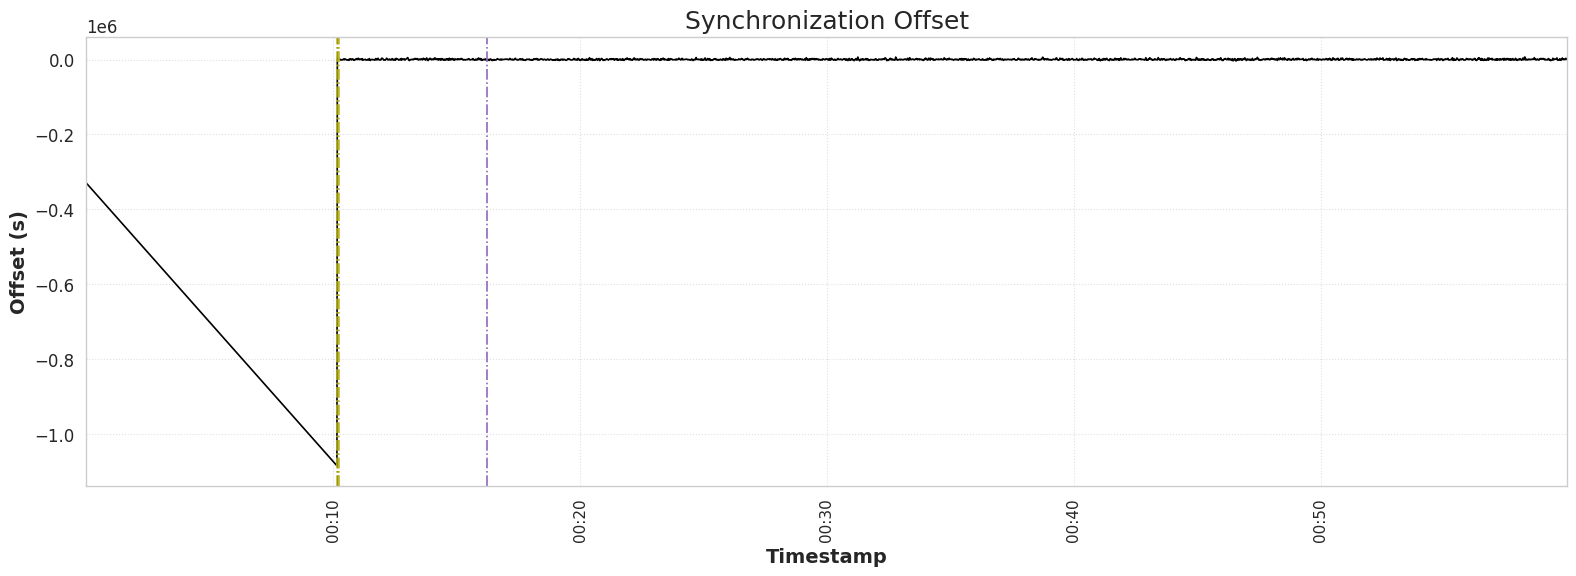

                    FR: 00:00:00.079997
Detección: T1 en el seg: 00:10:12.077794
                    T1: 00:10:11.069813
Detección: SY en el seg: 00:16:16.066956
                    SY: 00:10:17.069645
Ha tardado: 00:00:17.069645 en sincronizarse


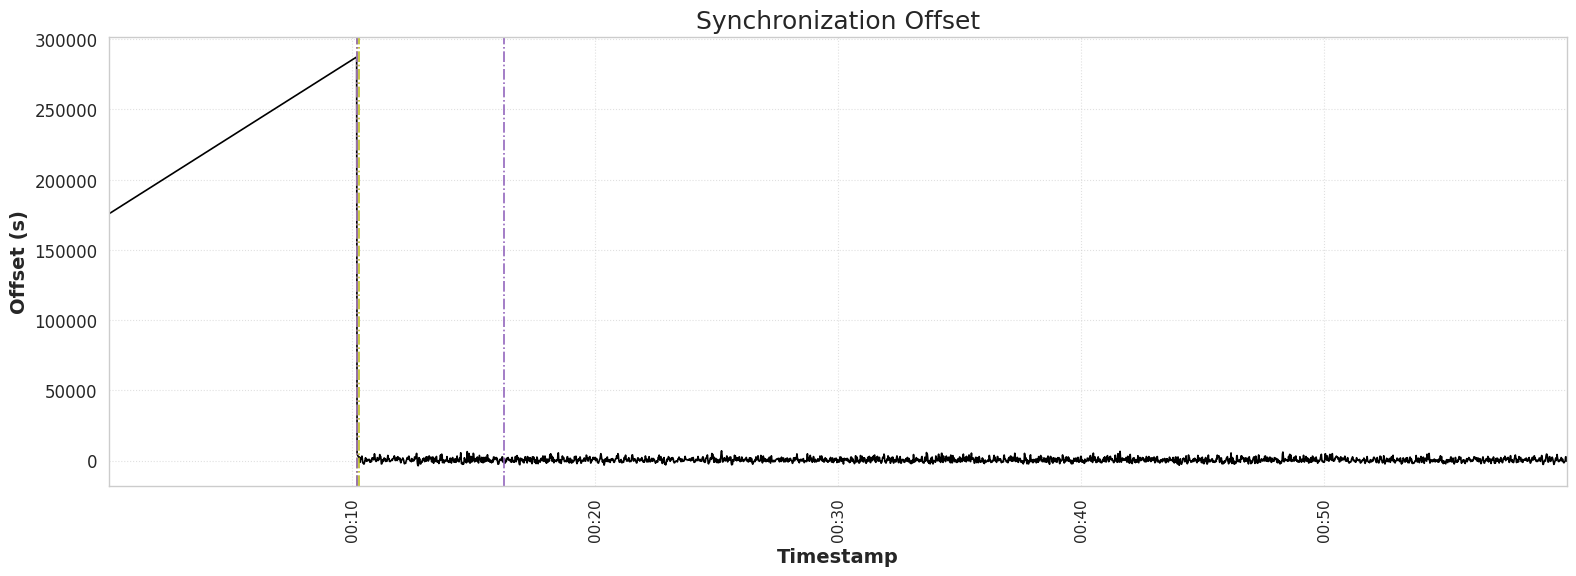

                    FR: 00:00:00.000000
Detección: T1 en el seg: 00:10:11.566020
                    T1: 00:10:09.998069
Detección: SY en el seg: 00:16:14.003358
                    SY: 00:10:15.565905
Ha tardado: 00:00:15.565905 en sincronizarse


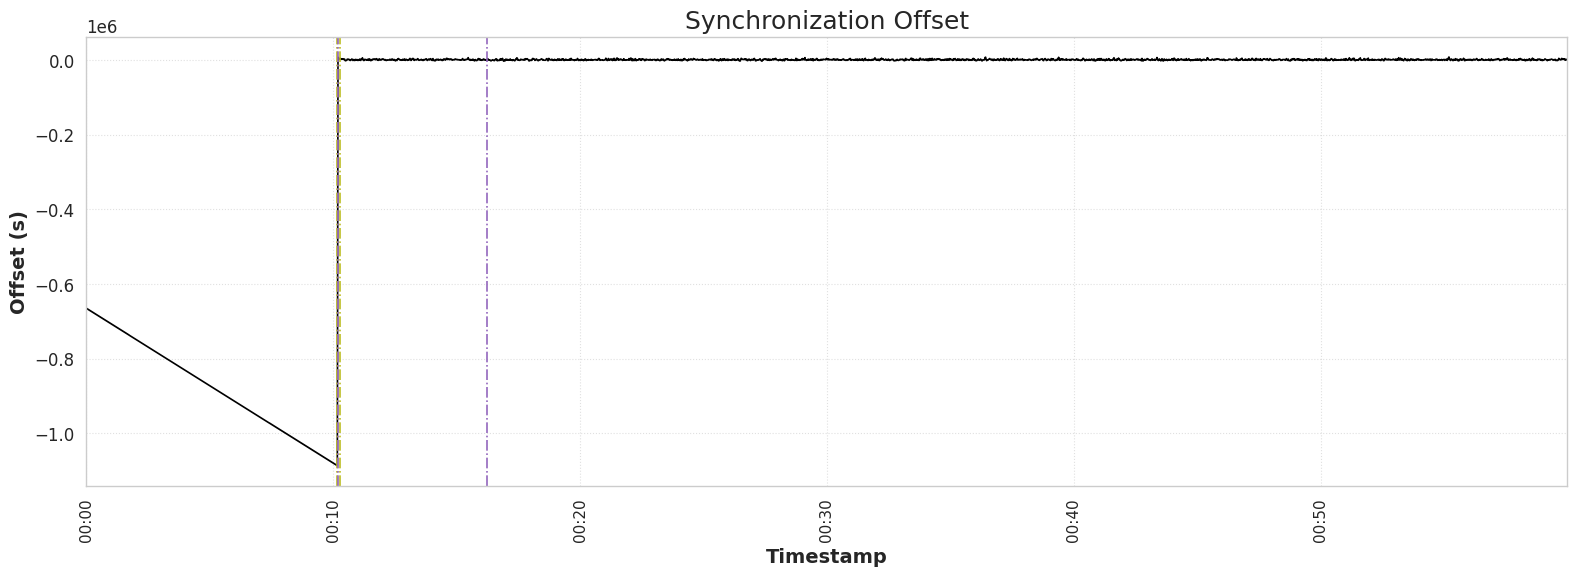

                    FR: 00:00:00.079991
Detección: T1 en el seg: 00:10:11.069849
                    T1: 00:10:10.077895
Detección: SY en el seg: 00:16:13.075135
                    SY: 00:10:14.077770
Ha tardado: 00:00:14.077770 en sincronizarse


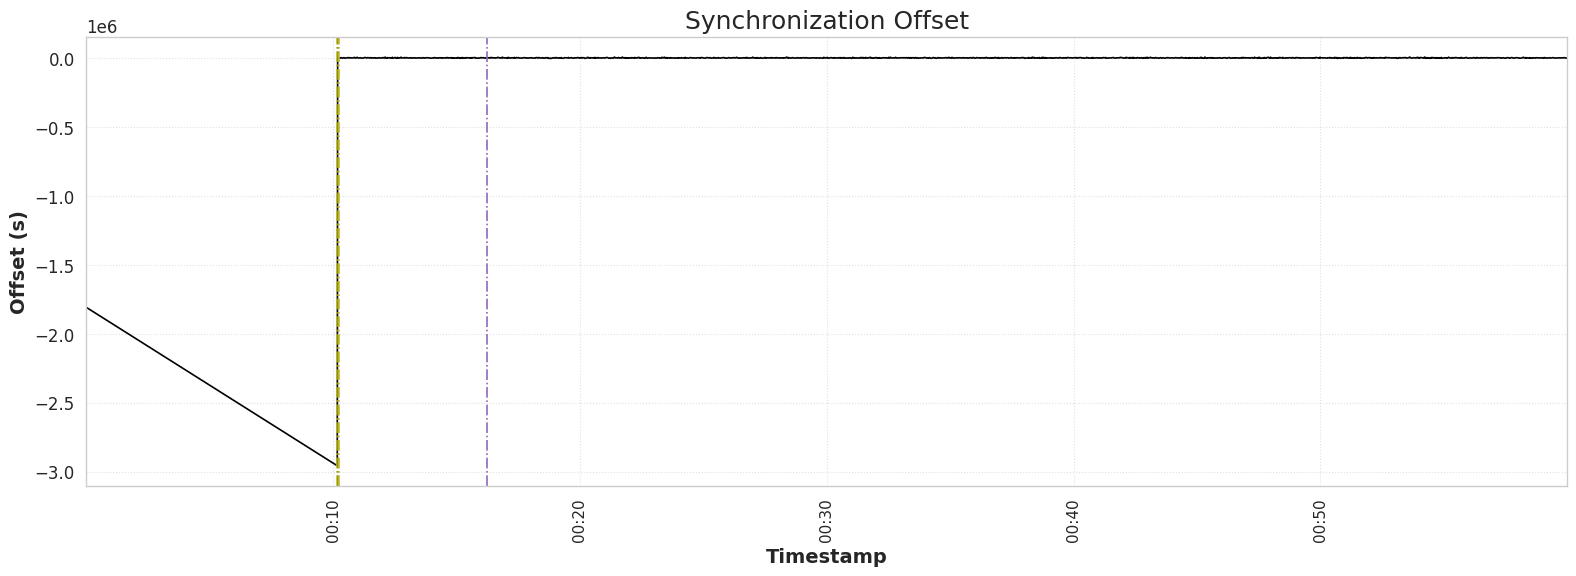

                    FR: 00:00:00.079998
Detección: T1 en el seg: 00:10:10.078083
                    T1: 00:10:09.086082
Detección: SY en el seg: 00:16:10.083414
                    SY: 00:10:11.086036
Ha tardado: 00:00:11.086036 en sincronizarse


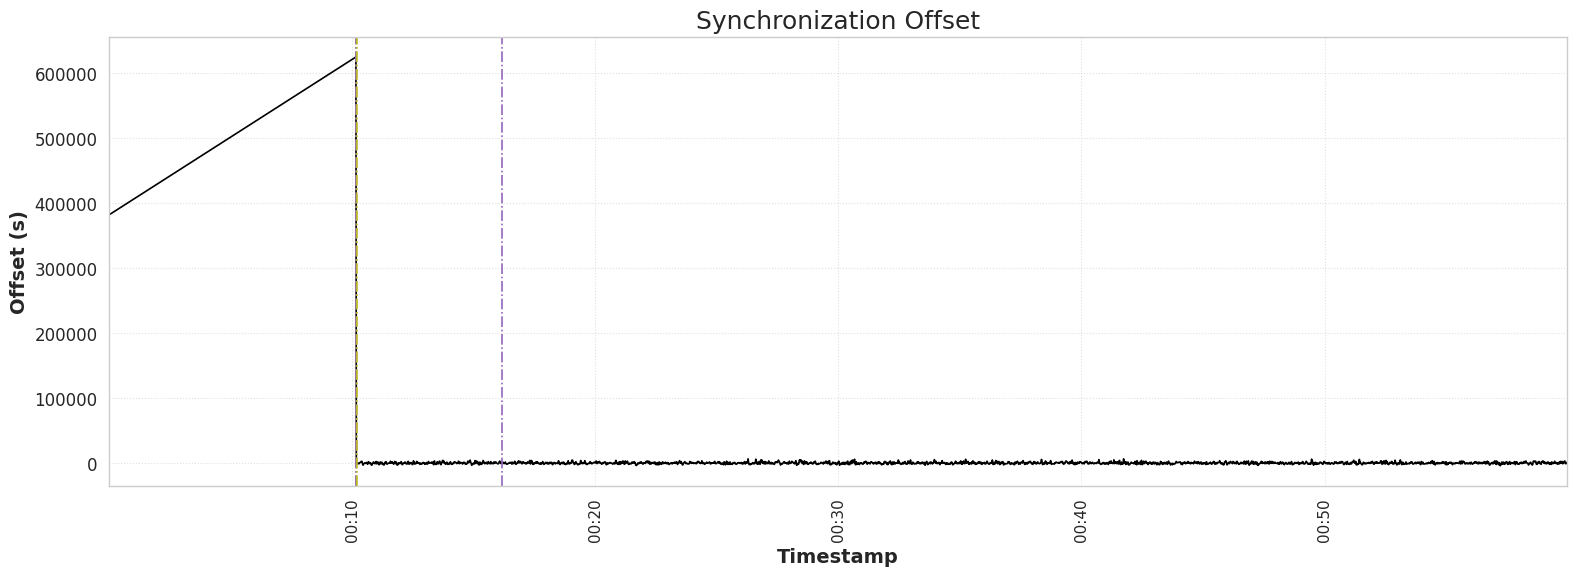

In [8]:


# Nombre de archivo a leer y nombre de la columna de offset a leer
th_cc = 0.90
window_proc = 360
client = "Intel710"


for i in range(5):
    SyRe_client = SyRe(datasets_75_by_time_TM3[0][i], window_proc, th_cc,client)
    SyRe_client.batch_SyRe()
    SyRe_client.print_graphs()


